<a href="https://colab.research.google.com/github/lnambiar18/Nambiar_Lohit_HW4_DSCI552/blob/main/Nambiar_Lohit_HW4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**bold text**<center><h1>Nambiar_Lohit_HW4</h1></center>
<br>
<br>

Name: Lohit Nambiar
<br>
Github Username: lnambiar18
<br>
USC ID: 8395177707

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [19]:
import pandas as pd
import os
import zipfile
import numpy as np
import seaborn as sn
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import roc_curve
from sklearn.metrics import auc
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_auc_score
from sklearn.naive_bayes import GaussianNB
from sklearn.naive_bayes import MultinomialNB

Get the AReM Data Set

In [2]:
if not os.path.exists("data/AReM"):
    with zipfile.ZipFile("AReM.zip") as z:
        z.extractall("data")

data_path = os.path.join("data", "AReM")

### (b) Splitting Data

In [3]:
folders = ["bending1", "bending2", "cycling", "lying", "sitting", "standing", "walking"]

train_data = []
test_data = []

for folder in folders:
    folder_path = os.path.join(data_path, folder)
    files = os.listdir(folder_path)

    for file in files:
        if file.endswith(".csv"):

            file_path = os.path.join(folder_path, file)

            df = pd.read_csv(file_path, skiprows=4, engine="python", on_bad_lines="skip")
            df = df.iloc[:, 1:7]

            df = df.apply(pd.to_numeric, errors="coerce")

            dataset_number = int(file.replace("dataset", "").replace(".csv", ""))

            df["activity"] = folder
            df["dataset"] = dataset_number

            if folder == "bending1" or folder == "bending2":
                test_numbers = [1, 2]
            else:
                test_numbers = [1, 2, 3]

            if dataset_number in test_numbers:
                test_data.append(df)
            else:
                train_data.append(df)

### (c) Feature Extraction

In [4]:
sensor_columns = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]

all_data = train_data + test_data

feature_data = []

for df in all_data:
    row = {}
    row["activity"] = df["activity"].iloc[0]
    row["dataset"] = df["dataset"].iloc[0]

    for column in sensor_columns:
        row["min_" + column] = df[column].min()
        row["max_" + column] = df[column].max()
        row["mean_" + column] = df[column].mean()
        row["median_" + column] = df[column].median()
        row["std_" + column] = df[column].std()
        row["first_quartile_" + column] = df[column].quantile(0.25)
        row["third_quartile_" + column] = df[column].quantile(0.75)

    feature_data.append(row)

feature_df = pd.DataFrame(feature_data)

feature_df.head()

np.random.seed(1018)

features = feature_df.columns[2:]
results = []

for feature in features:

    values = feature_df[feature].dropna()
    original_std = np.std(values, ddof=1)

    bootstrap_stds = []

    for i in range(1000):
        sample = np.random.choice(values, size=len(values), replace=True)
        sample_std = np.std(sample, ddof=1)
        bootstrap_stds.append(sample_std)

    lower = np.percentile(bootstrap_stds, 5)
    upper = np.percentile(bootstrap_stds, 95)

    results.append([feature, original_std, lower, upper])

confidence_int_df = pd.DataFrame(results, columns=["Feature", "Standard Deviation", "Lower Bound", "Upper Bound"])

confidence_int_df

,Feature,Standard Deviation,Lower Bound,Upper Bound
0,min_avg_rss12,9.624011,8.359238,10.839149
1,max_avg_rss12,4.207745,3.080960,5.160522
2,mean_avg_rss12,5.276413,4.616951,5.816673
3,median_avg_rss12,5.386624,4.728165,5.946951
4,std_avg_rss12,1.771313,1.566184,1.937702
5,first_quartile_avg_rss12,6.128143,5.549685,6.616385
6,third_quartile_avg_rss12,5.031028,4.182060,5.716581
7,min_var_rss12,0.000000,0.000000,0.000000
8,max_var_rss12,5.059656,4.608551,5.390245
9,mean_var_rss12,1.577941,1.418056,1.704969


## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

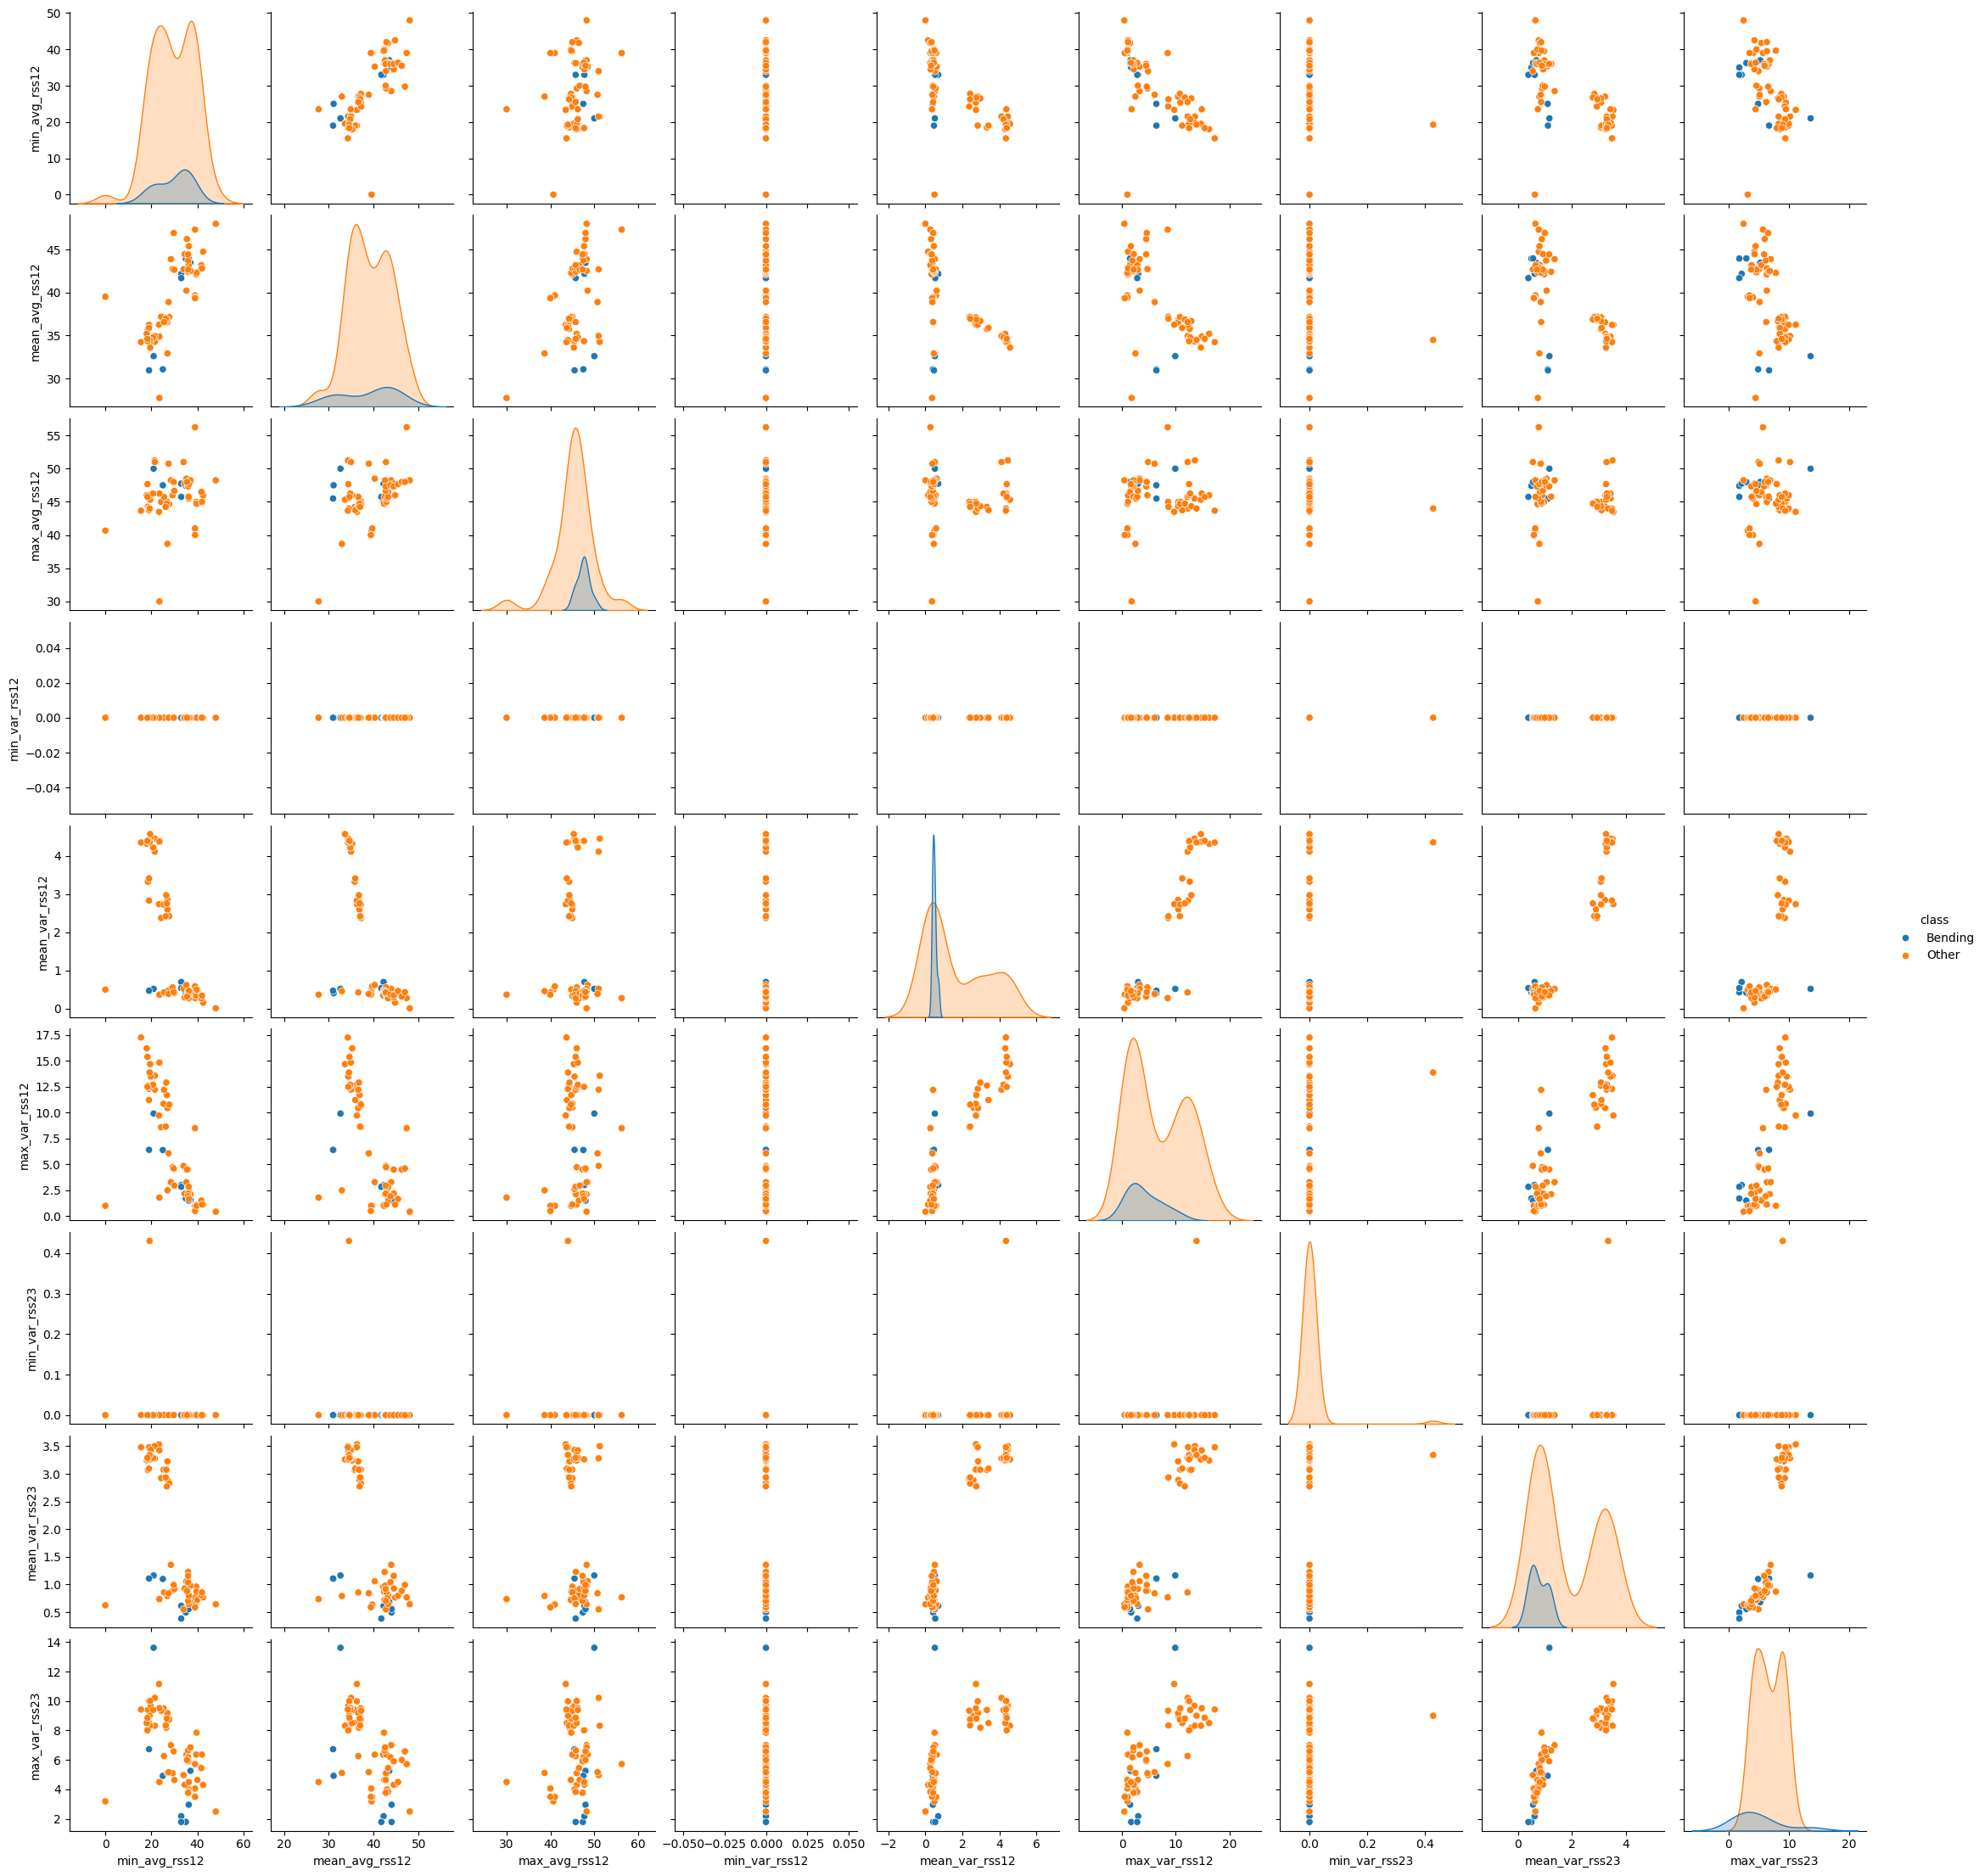

In [5]:
bending_train = feature_df[((feature_df["activity"] == "bending1") | (feature_df["activity"] == "bending2")) & (feature_df["dataset"] > 2)].copy()

bending_train["class"] = "Bending"

other_train = feature_df[(feature_df["activity"] != "bending1") & (feature_df["activity"] != "bending2") & (feature_df["dataset"] > 3)].copy()

other_train["class"] = "Other"

train_features = pd.concat([bending_train, other_train])

selected_features = [
    "min_avg_rss12",
    "mean_avg_rss12",
    "max_avg_rss12",

    "min_var_rss12",
    "mean_var_rss12",
    "max_var_rss12",

    "min_var_rss23",
    "mean_var_rss23",
    "max_var_rss23"
]

sn.pairplot(train_features[selected_features + ["class"]], hue="class")

plt.show()

#### ii. Splitted Plots

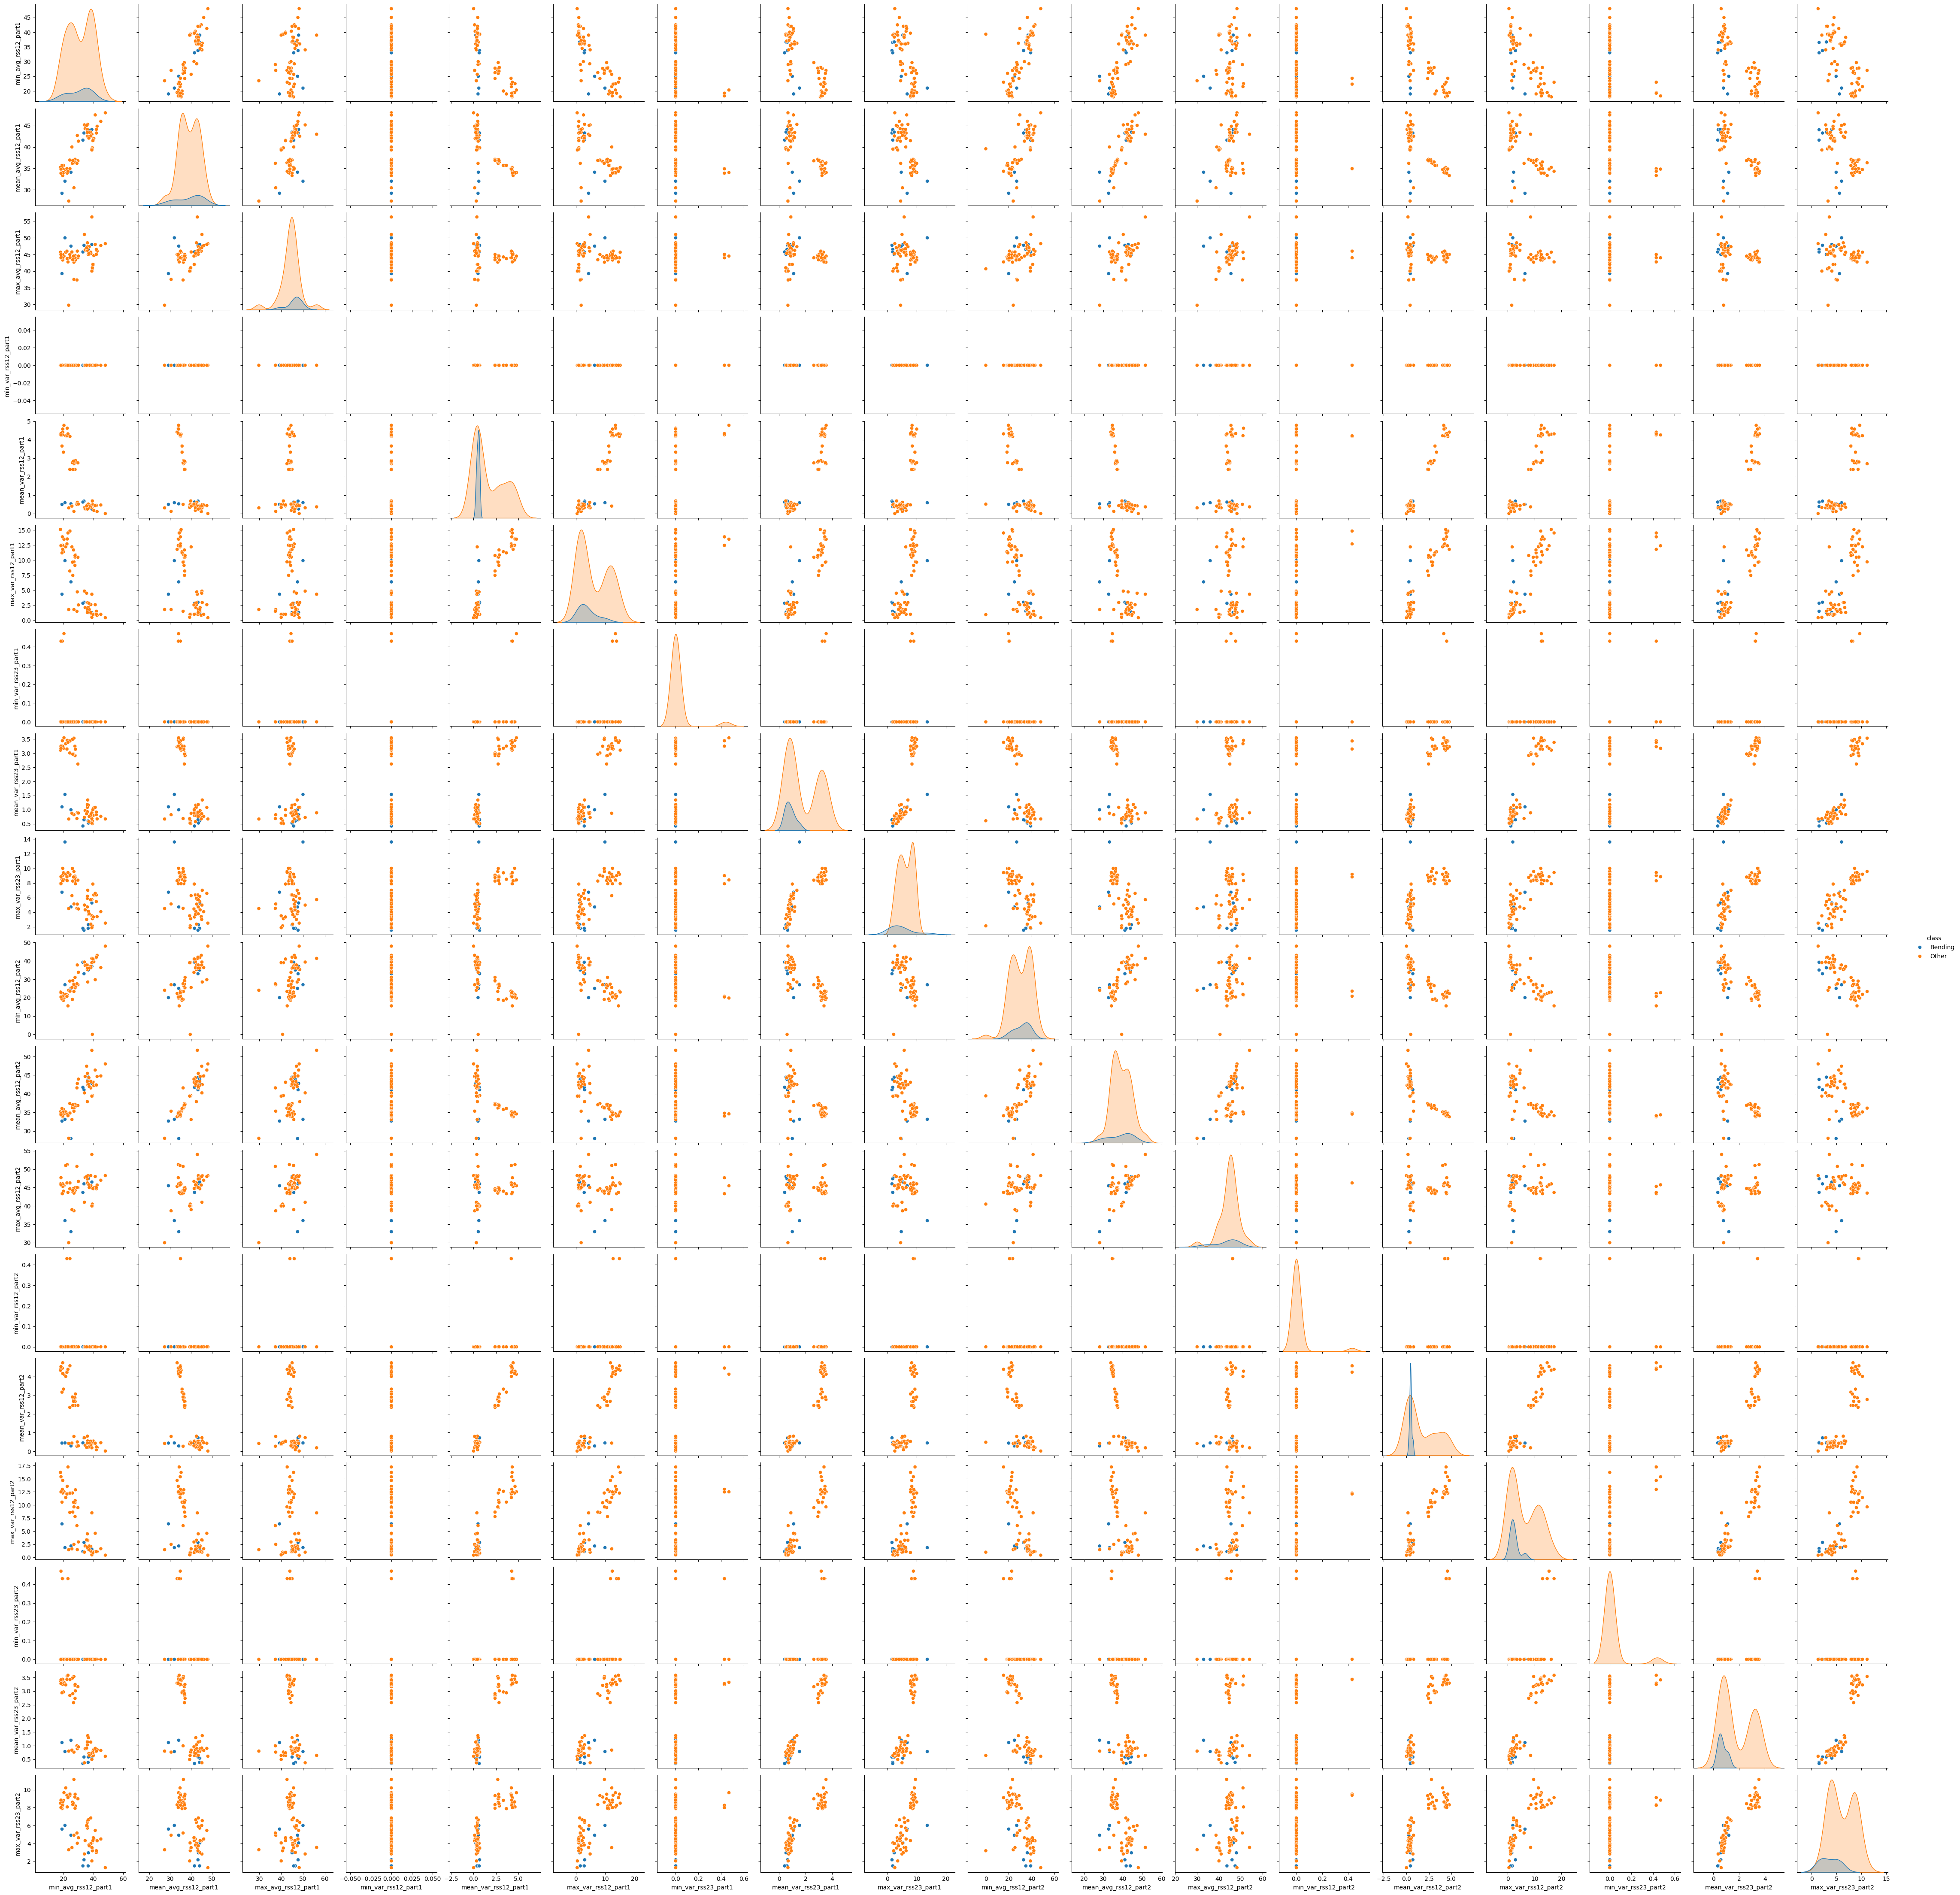

In [6]:
time_series = ["avg_rss12", "var_rss12", "var_rss23"]

new_features = []

for df in train_data:
    middle = len(df) // 2
    first_half = df.iloc[:middle]
    second_half = df.iloc[middle:]
    row = {}
    activity = df["activity"].iloc[0]

    if activity == "bending1" or activity == "bending2":
        row["class"] = "Bending"
    else:
        row["class"] = "Other"

    for column in time_series:

        row["min_" + column + "_part1"] = first_half[column].min()
        row["mean_" + column + "_part1"] = first_half[column].mean()
        row["max_" + column + "_part1"] = first_half[column].max()

        row["min_" + column + "_part2"] = second_half[column].min()
        row["mean_" + column + "_part2"] = second_half[column].mean()
        row["max_" + column + "_part2"] = second_half[column].max()

    new_features.append(row)

split_feature_df = pd.DataFrame(new_features)

selected_features = [
    "min_avg_rss12_part1",
    "mean_avg_rss12_part1",
    "max_avg_rss12_part1",
    "min_var_rss12_part1",
    "mean_var_rss12_part1",
    "max_var_rss12_part1",
    "min_var_rss23_part1",
    "mean_var_rss23_part1",
    "max_var_rss23_part1",
    "min_avg_rss12_part2",
    "mean_avg_rss12_part2",
    "max_avg_rss12_part2",
    "min_var_rss12_part2",
    "mean_var_rss12_part2",
    "max_var_rss12_part2",
    "min_var_rss23_part2",
    "mean_var_rss23_part2",
    "max_var_rss23_part2"
]

sn.pairplot(split_feature_df[selected_features + ["class"]], hue="class")

plt.show()

The plots look mostly similar to the original ones, since the bending points still overlap with the other activities in many of the scatter plots. Splitting the time series gave more features, but I do not see a major difference or much clearer separation between bending and the other activities.

#### iii. Time Series Segments

In [7]:
time_series = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]

def make_features(data, l):

    rows = []

    for df in data:

        row = {}

        activity = df["activity"].iloc[0]

        if activity == "bending1" or activity == "bending2":
            row["class"] = 1
        else:
            row["class"] = 0

        for column in time_series:
            pieces = np.array_split(df[column].to_numpy(), l)

            for i in range(l):

                piece = pieces[i]

                row["min_" + column + "_" + str(i + 1)] = piece.min()
                row["mean_" + column + "_" + str(i + 1)] = piece.mean()
                row["max_" + column + "_" + str(i + 1)] = piece.max()

        rows.append(row)

    return pd.DataFrame(rows)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1018)

p_values = [1, 3, 5, 10, 15]

results = []

for l in range(1, 21):

    data = make_features(train_data, l)

    y = data["class"]
    X = data.drop("class", axis=1)

    for p in p_values:
        if p > len(X.columns):
            continue

        logistic_model = LogisticRegression(solver="liblinear", max_iter=500, class_weight="balanced")

        rfe = RFE(estimator=logistic_model, n_features_to_select=p, step=0.2)

        model = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler()), ("rfe", rfe), ("logistic_regression", LogisticRegression(solver="liblinear", max_iter=500, class_weight="balanced"))])

        scores = cross_val_score(model, X.to_numpy(), y.to_numpy(), cv=cv, scoring="accuracy", n_jobs=-1)

        average_accuracy = scores.mean()

        results.append([l, p, average_accuracy])

results_df = pd.DataFrame(results, columns=["l", "p", "average_accuracy"])

results_df = results_df.sort_values("average_accuracy", ascending=False)

results_df.head()

,l,p,average_accuracy
3,1,10,0.942857
8,2,10,0.942857
6,2,3,0.942857
4,1,15,0.942857
13,3,10,0.928571


In [8]:
best_l = int(results_df.iloc[0]["l"])
best_p = int(results_df.iloc[0]["p"])

print("Best l:", best_l)
print("Best p:", best_p)
print("Best cross validation accuracy:", results_df.iloc[0]["average_accuracy"])

best_data = make_features(train_data, best_l)

y_train = best_data["class"]
X_train = best_data.drop("class", axis=1)

final_model = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler()), ("rfe", RFE(estimator=LogisticRegression(solver="liblinear", max_iter=500, class_weight="balanced"), n_features_to_select=best_p, step=0.2)), ("logistic_regression", LogisticRegression(solver="liblinear", max_iter=500, class_weight="balanced"))])

final_model.fit(X_train, y_train)


Best l: 1
Best p: 10
Best cross validation accuracy: 0.9428571428571428


Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('rfe',
                 RFE(estimator=LogisticRegression(class_weight='balanced',
                                                  max_iter=500,
                                                  solver='liblinear'),
                     n_features_to_select=10, step=0.2)),
                ('logistic_regression',
                 LogisticRegression(class_weight='balanced', max_iter=500,
                                    solver='liblinear'))])


I used stratified 5-fold cross-validation because there were fewer bending instances than other activity instances. This made sure each fold included both classes. The best model had l = 1 and p = 1, with an accuracy of about 97.14%. This means that not splitting the time series and using one feature selected by RFE worked best. The correct way to do cross-validation is to select features inside each training fold, while the wrong way is selecting features using all of the data before cross-validation because it can make the accuracy seem better than it actually is.

#### iv. Confusion Matrix

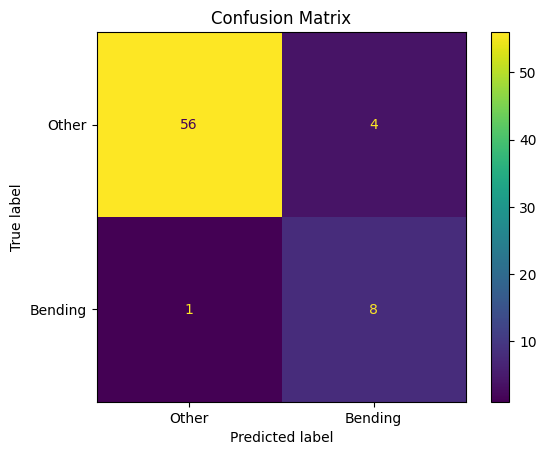

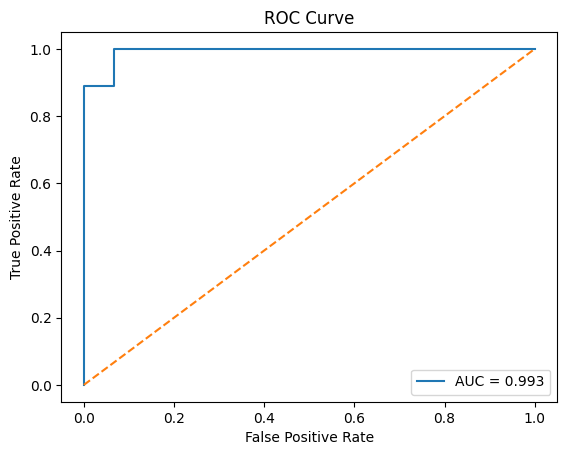

AUC: 0.9925925925925926
Selected feature: ['min_avg_rss12_1', 'mean_avg_rss12_1', 'max_avg_rss12_1', 'mean_var_rss12_1', 'max_avg_rss13_1', 'mean_var_rss13_1', 'min_avg_rss23_1', 'mean_avg_rss23_1', 'max_avg_rss23_1', 'mean_var_rss23_1']
Optimization terminated successfully.
         Current function value: 0.062415
         Iterations 13


,Parameter,Beta,P-value
const,Intercept,-11.487128,0.270442
x1,min_avg_rss12_1,-3.169606,0.512269
x2,mean_avg_rss12_1,-0.578958,0.822031
x3,max_avg_rss12_1,1.209018,0.505556
x4,mean_var_rss12_1,-15.696988,0.505604
x5,max_avg_rss13_1,8.707927,0.480237
x6,mean_var_rss13_1,22.619928,0.361599
x7,min_avg_rss23_1,0.885591,0.760654
x8,mean_avg_rss23_1,-1.210882,0.722913
x9,max_avg_rss23_1,-2.060978,0.657444


In [9]:
predictions = final_model.predict(X_train)

probabilities = final_model.predict_proba(X_train)[:, 1]

cm = confusion_matrix(y_train, predictions)
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Other", "Bending"])
display.plot()

plt.title("Confusion Matrix")
plt.show()

fpr, tpr, thresholds = roc_curve(y_train, probabilities)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label="AUC = " + str(round(roc_auc, 3)))
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()

plt.show()

print("AUC:", roc_auc)

selected_features = X_train.columns[final_model.named_steps["rfe"].support_]

print("Selected feature:", list(selected_features))

imputer = final_model.named_steps["imputer"]
scaler = final_model.named_steps["scaler"]
rfe = final_model.named_steps["rfe"]

X_imputed = imputer.transform(X_train)
X_scaled = scaler.transform(X_imputed)
X_selected = X_scaled[:, rfe.support_]

X_selected = sm.add_constant(X_selected)

statsmodel = sm.Logit(y_train, X_selected).fit()

parameter_names = ["Intercept"] + list(selected_features)

parameters_df = pd.DataFrame({"Parameter": parameter_names, "Beta": statsmodel.params, "P-value": statsmodel.pvalues})
parameters_df

#### v. Test Classifier

In [10]:
test_features = make_features(test_data, best_l)

y_test = test_features["class"]
X_test = test_features.drop("class", axis=1)

test_predictions = final_model.predict(X_test)

test_accuracy = accuracy_score(y_test, test_predictions)

print("Cross-validation accuracy:", results_df.iloc[0]["average_accuracy"])
print("Test accuracy:", test_accuracy)

Cross-validation accuracy: 0.9428571428571428
Test accuracy: 1.0


The test accuracy was about 94.74%, while the cross-validation accuracy was about 97.14%. The test accuracy was slightly lower, but it was still very close to the cross-validation accuracy, showing that the model was able to classify the test data well.

#### vi. Separation

The classes seem mostly well-separated because the model had high cross-validation and test accuracy. However, they do not seem completely separated since the test accuracy was not 100%, so there should not be major instability when calculating the logistic regression parameters.

#### vii. Imbalance

Selected feature: min_avg_rss12_1
Bending: 9
Other: 9
Original intercept: -0.000920294962856802
Adjusted intercept: -1.8980402798487381
Beta: 0.21272443688568507


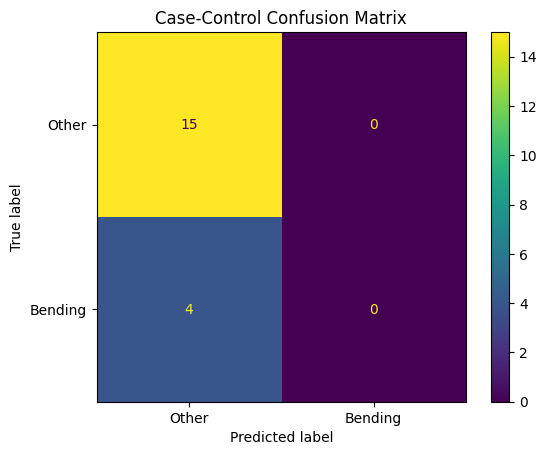

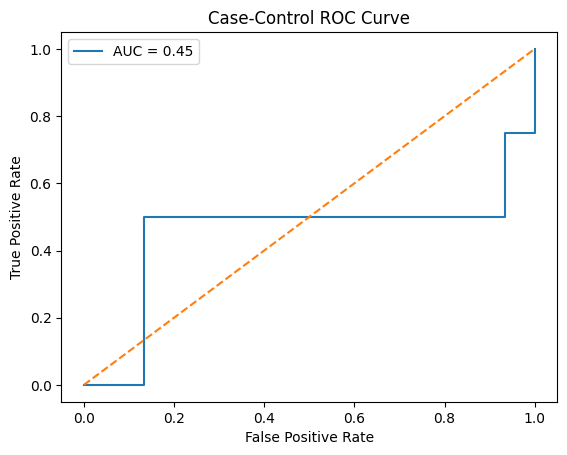

AUC: 0.45


In [11]:
selected_feature = X_train.columns[final_model.named_steps["rfe"].support_][0]

print("Selected feature:", selected_feature)

bending_data = best_data[best_data["class"] == 1]
other_data = best_data[best_data["class"] == 0]

other_sample = other_data.sample(n=len(bending_data), random_state=1018)

case_control_data = pd.concat([bending_data,other_sample])

X_case = case_control_data[[selected_feature]]
y_case = case_control_data["class"]

print("Bending:", sum(y_case == 1))
print("Other:", sum(y_case == 0))

imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

X_case = imputer.fit_transform(X_case)
X_case = scaler.fit_transform(X_case)

X_test_one_feature = X_test[[selected_feature]]

X_test_one_feature = imputer.transform(X_test_one_feature)
X_test_one_feature = scaler.transform(X_test_one_feature)

case_model = LogisticRegression(solver="liblinear", max_iter=500)

case_model.fit(X_case, y_case)

original_bending_rate = y_train.mean()
sample_bending_rate = y_case.mean()

adjustment = np.log((original_bending_rate / (1 - original_bending_rate)) / (sample_bending_rate / (1 - sample_bending_rate)))

adjusted_intercept = case_model.intercept_[0] + adjustment

print("Original intercept:", case_model.intercept_[0])
print("Adjusted intercept:", adjusted_intercept)
print("Beta:", case_model.coef_[0][0])

scores = case_model.decision_function(X_test_one_feature)
scores = scores + adjustment
probabilities = 1 / (1 + np.exp(-scores))
predictions = (probabilities >= 0.5).astype(int)

cm = confusion_matrix(y_test, predictions)

display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Other", "Bending"])
display.plot()
plt.title("Case-Control Confusion Matrix")
plt.show()

fpr, tpr, thresholds = roc_curve(y_test, probabilities)

roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label="AUC = " + str(round(roc_auc, 3)))
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Case-Control ROC Curve")
plt.legend()
plt.show()

print("AUC:", roc_auc)

After case-control sampling, I used 9 Bending and 9 Other instances. The selected feature was max_avg_rss23_1, the adjusted intercept was -1.871, and the beta value was 1.902. On the test data, the confusion matrix showed 15 correctly classified Other instances, 2 correctly classified Bending instances, and 2 Bending instances classified as Other. The ROC curve had an AUC of 1.0, meaning the model was able to rank the two classes well, even though the 0.5 cutoff missed two Bending instances.

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1018)

C_values = [0.01, 0.1, 1, 10, 100]

results = []

for l in range(1, 21):

    data = make_features(train_data, l)

    y = data["class"]
    X = data.drop("class", axis=1)

    for C in C_values:
        model = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler()), ("logistic_regression", LogisticRegression(penalty="l1", solver="liblinear", C=C, max_iter=1000, class_weight="balanced"))])
        scores = cross_val_score(model, X.to_numpy(), y.to_numpy(), cv=cv, scoring="accuracy")
        average_accuracy = scores.mean()
        results.append([l, C, average_accuracy])

results_df_l1 = pd.DataFrame(results, columns=["l", "C", "average_accuracy"])
results_df_l1 = results_df_l1.sort_values("average_accuracy", ascending=False)
results_df_l1.head()

best_l_l1 = int(results_df_l1.iloc[0]["l"])
best_C_l1 = results_df_l1.iloc[0]["C"]

print("Best l:", best_l_l1)
print("Best C:", best_C_l1)
print("Best cross-validation accuracy:", results_df_l1.iloc[0]["average_accuracy"])

best_data_l1 = make_features(train_data, best_l_l1)

y_train_l1 = best_data_l1["class"]
X_train_l1 = best_data_l1.drop("class", axis=1)

final_l1_model = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler()), ("logistic_regression", LogisticRegression(penalty="l1", solver="liblinear",C=best_C_l1, max_iter=1000, class_weight="balanced"))])

final_l1_model.fit(X_train_l1, y_train_l1)

Best l: 3
Best C: 10.0
Best cross-validation accuracy: 0.9571428571428571


Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('logistic_regression',
                 LogisticRegression(C=np.float64(10.0), class_weight='balanced',
                                    max_iter=1000, penalty='l1',
                                    solver='liblinear'))])

#### ii. Comparison

The earlier variable selection model performed slightly better because it had a cross-validation accuracy of about 97.14%, compared to about 95.71% for the L1-penalized model. However, the L1 model was easier to implement because it automatically selects important features by shrinking unimportant feature coefficients to zero.

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default 

Best l: 1
Best C: 1.0
Best cross-validation accuracy: 0.8978021978021978
Test accuracy: 0.8947368421052632
Test error: 0.10526315789473684


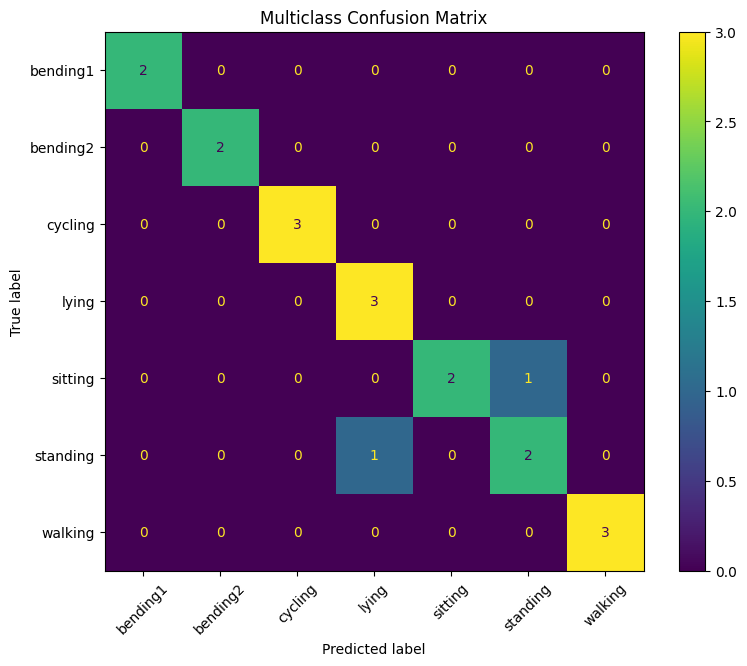

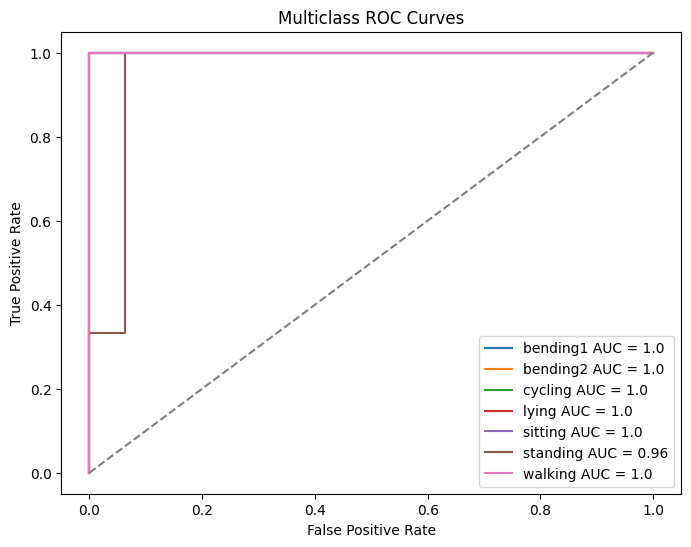

Macro-average AUC: 0.994047619047619


In [18]:
time_series = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]

def make_multiclass_features(data, l):
    rows = []
    for df in data:
        row = {}
        row["activity"] = df["activity"].iloc[0]
        for column in time_series:
            pieces = np.array_split(df[column].to_numpy(), l)
            for i in range(l):
                piece = pieces[i]
                row["min_" + column + "_" + str(i + 1)] = piece.min()
                row["mean_" + column + "_" + str(i + 1)] = piece.mean()
                row["max_" + column + "_" + str(i + 1)] = piece.max()

        rows.append(row)

    return pd.DataFrame(rows)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1018)

C_values = [0.01, 0.1, 1, 10]

results = []

for l in range(1, 21):

    data = make_multiclass_features(train_data, l)

    y = data["activity"]
    X = data.drop("activity", axis=1)

    for C in C_values:

        model = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler()), ("logistic_regression", LogisticRegression(penalty="l1", solver="saga", multi_class="multinomial", C=C, max_iter=3000, class_weight="balanced"))])

        scores = cross_val_score(model, X.to_numpy(), y.to_numpy(), cv=cv, scoring="accuracy")

        average_accuracy = scores.mean()

        results.append([l, C, average_accuracy])

results_df_multi = pd.DataFrame(results, columns=["l", "C", "average_accuracy"])
results_df_multi = results_df_multi.sort_values("average_accuracy",ascending=False)
results_df_multi.head()

best_l_multi = int(results_df_multi.iloc[0]["l"])
best_C_multi = results_df_multi.iloc[0]["C"]

print("Best l:", best_l_multi)
print("Best C:", best_C_multi)
print("Best cross-validation accuracy:", results_df_multi.iloc[0]["average_accuracy"])

train_multi = make_multiclass_features(train_data, best_l_multi)

test_multi = make_multiclass_features(test_data, best_l_multi)

y_train_multi = train_multi["activity"]
X_train_multi = train_multi.drop("activity", axis=1)

y_test_multi = test_multi["activity"]
X_test_multi = test_multi.drop("activity", axis=1)

final_multi_model = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler()), ("logistic_regression", LogisticRegression(penalty="l1", solver="saga", multi_class="multinomial", C=best_C_multi, max_iter=3000, class_weight="balanced"))])
final_multi_model.fit(X_train_multi, y_train_multi)

test_predictions = final_multi_model.predict(X_test_multi)
test_accuracy = accuracy_score(y_test_multi, test_predictions)
test_error = 1 - test_accuracy

print("Test accuracy:", test_accuracy)
print("Test error:", test_error)

activity_names = final_multi_model.named_steps["logistic_regression"].classes_

cm = confusion_matrix(y_test_multi, test_predictions, labels=activity_names)

display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=activity_names)
fig, ax = plt.subplots(figsize=(9, 7))
display.plot(ax=ax)
plt.xticks(rotation=45)
plt.title("Multiclass Confusion Matrix")
plt.show()

probabilities = final_multi_model.predict_proba(X_test_multi)

y_test_binary = label_binarize(y_test_multi, classes=activity_names)

plt.figure(figsize=(8, 6))
for i in range(len(activity_names)):

    fpr, tpr, thresholds = roc_curve(y_test_binary[:, i], probabilities[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=activity_names[i] + " AUC = " + str(round(roc_auc, 2)))

plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass ROC Curves")
plt.legend()

plt.show()

macro_auc = roc_auc_score(y_test_binary, probabilities, average="macro", multi_class="ovr")
print("Macro-average AUC:", macro_auc)

#### ii. Naive Bayes

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklea

Gaussian Naive Bayes
   l  average_accuracy
1  2          0.883516
0  1          0.869231
2  3          0.812088
3  4          0.796703
4  5          0.783516
Multinomial Naive Bayes
     l  average_accuracy
11  12          0.826374
7    8          0.826374
12  13          0.825275
10  11          0.810989
5    6          0.797802
Best Gaussian l: 2
Best Multinomial l: 12
Gaussian test error: 0.10526315789473684
Multinomial test error: 0.21052631578947367


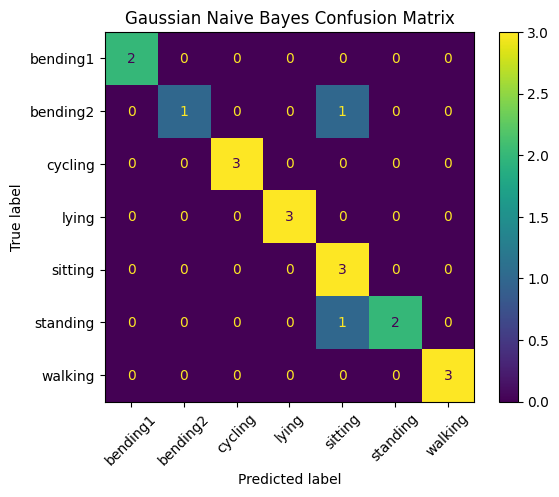

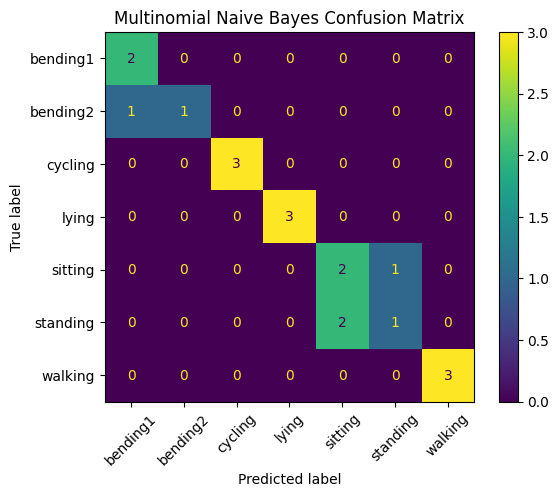

In [20]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1018)

gaussian_results = []
multinomial_results = []

for l in range(1, 21):
    data = make_multiclass_features(train_data, l)

    y = data["activity"]
    X = data.drop("activity", axis=1)

    gaussian_model = Pipeline([("imputer", SimpleImputer(strategy="median")), ("naive_bayes", GaussianNB())])
    gaussian_scores = cross_val_score(gaussian_model, X.to_numpy(), y.to_numpy(), cv=cv, scoring="accuracy")
    gaussian_results.append([l, gaussian_scores.mean()])

    multinomial_model = Pipeline([("imputer", SimpleImputer(strategy="median")), ("naive_bayes", MultinomialNB())])
    multinomial_scores = cross_val_score(multinomial_model, X.to_numpy(), y.to_numpy(), cv=cv, scoring="accuracy")
    multinomial_results.append([l, multinomial_scores.mean()])

gaussian_results_df = pd.DataFrame(gaussian_results, columns=["l", "average_accuracy"])
multinomial_results_df = pd.DataFrame(multinomial_results, columns=["l", "average_accuracy"])
gaussian_results_df = gaussian_results_df.sort_values("average_accuracy", ascending=False)
multinomial_results_df = multinomial_results_df.sort_values( "average_accuracy", ascending=False)

print("Gaussian Naive Bayes")
print(gaussian_results_df.head())

print("Multinomial Naive Bayes")
print(multinomial_results_df.head())

best_l_gaussian = int(gaussian_results_df.iloc[0]["l"])
best_l_multinomial = int(multinomial_results_df.iloc[0]["l"])

print("Best Gaussian l:", best_l_gaussian)
print("Best Multinomial l:", best_l_multinomial)

train_gaussian = make_multiclass_features(train_data, best_l_gaussian)
test_gaussian = make_multiclass_features(test_data, best_l_gaussian)

X_train_gaussian = train_gaussian.drop("activity", axis=1)
y_train_gaussian = train_gaussian["activity"]

X_test_gaussian = test_gaussian.drop("activity", axis=1)
y_test_gaussian = test_gaussian["activity"]

gaussian_model = Pipeline([("imputer", SimpleImputer(strategy="median")), ("naive_bayes", GaussianNB())])
gaussian_model.fit(X_train_gaussian, y_train_gaussian)
gaussian_predictions = gaussian_model.predict(X_test_gaussian)
gaussian_accuracy = accuracy_score(y_test_gaussian, gaussian_predictions)

print("Gaussian test error:", 1 - gaussian_accuracy)

train_multinomial = make_multiclass_features(train_data, best_l_multinomial)
test_multinomial = make_multiclass_features(test_data, best_l_multinomial)
X_train_multinomial = train_multinomial.drop("activity", axis=1)
y_train_multinomial = train_multinomial["activity"]
X_test_multinomial = test_multinomial.drop("activity", axis=1)
y_test_multinomial = test_multinomial["activity"]

multinomial_model = Pipeline([("imputer", SimpleImputer(strategy="median")), ("naive_bayes", MultinomialNB())])
multinomial_model.fit(X_train_multinomial, y_train_multinomial)

multinomial_predictions = multinomial_model.predict(X_test_multinomial)
multinomial_accuracy = accuracy_score(y_test_multinomial, multinomial_predictions)

print("Multinomial test error:", 1 - multinomial_accuracy)

gaussian_classes = gaussian_model.named_steps["naive_bayes"].classes_
gaussian_cm = confusion_matrix(y_test_gaussian, gaussian_predictions, labels=gaussian_classes)
ConfusionMatrixDisplay(confusion_matrix=gaussian_cm, display_labels=gaussian_classes).plot()
plt.title("Gaussian Naive Bayes Confusion Matrix")
plt.xticks(rotation=45)
plt.show()

multinomial_classes = multinomial_model.named_steps["naive_bayes"].classes_
multinomial_cm = confusion_matrix(y_test_multinomial, multinomial_predictions, labels=multinomial_classes)
ConfusionMatrixDisplay(confusion_matrix=multinomial_cm, display_labels=multinomial_classes).plot()
plt.title("Multinomial Naive Bayes Confusion Matrix")
plt.xticks(rotation=45)
plt.show()

#### ii. Comparison

The L1-penalized multinomial logistic regression was the best overall method because it had the highest cross-validation accuracy of about 89.78% and a macro-average AUC of about 0.994. Gaussian Naive Bayes was very close, since it had the same test error of about 10.53%, but its cross-validation accuracy was slightly lower. Multinomial Naive Bayes performed the worst because its test error was about 21.05%.

## 3. ISLR 4.8.3

In QDA, each class has its own mean and its own variance. When the probability formula for each class is expanded, it includes an x^2 term that is divided by that class’s variance. Since the variances can be different between classes, the x^2 terms are different and do not cancel when comparing one class to another. This makes the decision boundary quadratic instead of linear. In LDA, all classes are assumed to have the same variance, so the x^2 terms cancel out and the decision boundary becomes linear.

## 4. ISLR 4.8.7

For a company with X=4, its profit is closer to the average profit of companies that did not issue dividends, which was 0, than companies that did issue dividends, which was 10. However, 80% of companies issued dividends, so the prior probability of issuing a dividend is much higher. Using Bayes’ theorem and the normal distribution values, the probability that the company will issue a dividend is about 75.2%.

## 5.1. Extra Practice ISLR 4.8.4

## 5.2. Extra Practice ISLR 4.8.9